# Corr_labpm_ctmc: fixed-time samples from an exact LABP-M CTMC

This notebook simulates LABP-M with the exact Gillespie direct method and
observes each independent trajectory on the common physical-time grid
\(t_j=t_{\rm burn}+j\,\Delta t\).  `DELTA_T` is an observation interval,
**not** a numerical integration step or a tau-leap approximation.

For interval `j`, `true_ep[m, j]` is the exact microscopic medium path
entropy accumulated by every actual event in
\((t_j,t_{j+1}]\):

\[
\mathrm{true\_ep}_{m,j}=\sum_{e\in(t_j,t_{j+1}]}
\log\frac{w(X_{e^-}\to X_e)}{w(X_e\to X_{e^-})}.
\]

The simulator returns this directly as `result.medium_ep`; it is never
reconstructed from the two sampled endpoints.  A bin can contain no
events, several events, or a round trip whose endpoints are identical.
All such bins remain in training.  Lateral hops and rotations have zero
medium EP here, but are still executed CTMC events.

Training is unsupervised alpha-NEEP on sampled endpoint pairs.  The true
medium EP is held out as a diagnostic rather than used as a regression
target: temporal coarse graining can hide paths, and the optimal endpoint
score also includes a stationary endpoint-distribution term.

Set `LABPM_SMOKE=1` for a small end-to-end run.  Set `LABPM_BACKEND` to
`cpu`, `cuda`, or `auto`; simulation and PyTorch training select their
devices independently.


In [31]:
import os

# Set LABPM_GPU_ID before importing torch/Numba; restart after changing it.
GPU_ID = os.environ.get("LABPM_GPU_ID", "0").strip()
if GPU_ID:
    if not GPU_ID.isdigit():
        raise ValueError("LABPM_GPU_ID must be one non-negative physical GPU index")
    os.environ["CUDA_VISIBLE_DEVICES"] = GPU_ID

import sys
import json
import math
import hashlib
import warnings
from pathlib import Path
from datetime import datetime, timezone
from dataclasses import asdict
from types import SimpleNamespace

ROOT = Path("/home/user1/projects/CNEEP_v2")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from tqdm.auto import trange
from data.labp_m import (
    LABPMConfig, LABPMResult, encode_observations,
    simulate_ensemble, simulation_backend,
)
from models.NEEP_ShellForce_2D import MultiScaleShellForceCNEEP2D

SMOKE = os.environ.get("LABPM_SMOKE", "0") == "1"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, os.cpu_count() or 1))
torch.manual_seed(2026)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(2026)
print("Project:", ROOT)
print("Training device:", DEVICE, "| physical GPU request:", GPU_ID or "default", "| smoke:", SMOKE)


Project: /home/user1/projects/CNEEP_v2
Training device: cuda | physical GPU request: 0 | smoke: False


## 1. Physics and fixed physical-time sampling

`N_INTERVALS` adjacent pairs are saved for every independent replica, so
`N_FRAMES = N_INTERVALS + 1`.  Frame zero is the state at the end of
`BURN_TIME`, and all burn-in EP is discarded.  Changing `DELTA_T` changes
only the observation grid; the exact pending Gillespie event survives a
frame boundary.

Train/validation/test are disjoint ensembles of replicas.  Uniformly
sampling their bins is uniform physical-time sampling, unlike the
event-indexed `Corr_labpm.ipynb` notebook.


In [32]:
config = LABPMConfig(
    lattice_size=10 if SMOKE else 30,
    density=0.20,
    forward_rate=1.0,
    backward_rate=1.0,
    lateral_rate=1.0,
    rotation_rate=0.1,
    shell_weights=(0.0, 0.0, 1.0),  # beta_2, beta_3, beta_4
)

TRAIN_M, VAL_M, TEST_M = (4, 2, 2) if SMOKE else (2048, 256, 16)
N_INTERVALS = 16 if SMOKE else 1024
DELTA_T = 0.04 if SMOKE else 15e-4
N_FRAMES = N_INTERVALS + 1
BURN_TIME = 0.1 if SMOKE else 500.0
SIMULATION_BACKEND_REQUEST = os.environ.get("LABPM_BACKEND", "auto").strip().lower()
SIMULATION_BACKEND = simulation_backend(SIMULATION_BACKEND_REQUEST)
CUDA_BATCH_SIZE = int(os.environ.get("LABPM_CUDA_BATCH_SIZE", "1024"))
WORKERS = int(os.environ["LABPM_WORKERS"]) if "LABPM_WORKERS" in os.environ else None
SPLIT_SEEDS = {"train": 12031, "validation": 23041, "test": 34057}
CACHE_DATA = not SMOKE
FORCE_RESIMULATE = False

# The model has a local branch plus exclusive Chebyshev-shell branches.
R = len(config.shell_weights) + 1
AREA = config.lattice_size**2
MODEL_MAX_DISTANCE = min(R + 1, (config.lattice_size - 1) // 2)
opt = SimpleNamespace(
    n_components=4, n_channel=8 if SMOKE else 128, n_hidden=4,
    max_distance=MODEL_MAX_DISTANCE, include_k0=True,
    positional=False, beta=0.0, shell_center_mode="relative_only",
    shell_relative_mode="learned_absolute", shell_force_bias=True,
    shell_weight_normalization="none", shell_force_activation="elu",
)
N_ITER = 3 if SMOKE else 4000
BATCH_SIZE = 8 if SMOKE else 2048
EVAL_BATCH_SIZE = 16 if SMOKE else 2048
RECORD_EVERY = 1 if SMOKE else 50
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-5
ALPHA = -0.5
CLIP_NORM = 10.0
TRAIN_SEED = 1

if min(TRAIN_M, VAL_M, TEST_M) < 2:
    raise ValueError("Use at least two independent trajectories in every split.")
if N_INTERVALS < 2 or not math.isfinite(DELTA_T) or DELTA_T <= 0:
    raise ValueError("Use at least two intervals and a finite positive DELTA_T.")
if not math.isfinite(BURN_TIME) or BURN_TIME < 0:
    raise ValueError("BURN_TIME must be finite and non-negative.")
if MODEL_MAX_DISTANCE >= config.lattice_size / 2:
    raise ValueError("Model shells must not wrap around the periodic lattice.")
assert len(set(SPLIT_SEEDS.values())) == 3

RESULT_BASE = Path(os.environ.get("LABPM_OUTPUT_DIR", str(ROOT / "results"))).expanduser()
result_name = "Corr_labpm_ctmc_smoke" if SMOKE else "Corr_labpm_ctmc"
RESULT_DIR = RESULT_BASE / result_name / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
RESULT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR = Path(os.environ.get("LABPM_CACHE_DIR", str(ROOT / "data" / "labp_m" / "cache"))).expanduser()
SANITY_SOURCE_PATH = ROOT / "data" / "labp_m" / "sanity_check_labpm.ipynb"
SANITY_SOURCE_HASH = hashlib.sha256(SANITY_SOURCE_PATH.read_bytes()).hexdigest()

print(json.dumps(asdict(config), indent=2))
print(f"Simulation: {SIMULATION_BACKEND} (requested {SIMULATION_BACKEND_REQUEST}); training: {DEVICE}")
print(f"CPU workers={WORKERS if WORKERS is not None else 'auto'}; CUDA replica batch size={CUDA_BATCH_SIZE}")
print(f"Independent replicas: train={TRAIN_M}, validation={VAL_M}, test={TEST_M}")
print(f"Dataset: {N_INTERVALS} fixed intervals x DELTA_T={DELTA_T:g}; burn={BURN_TIME:g}")
print("true_ep is the in-bin sum of actual event medium EP; it is diagnostic only.")
print("Results:", RESULT_DIR)


{
  "lattice_size": 30,
  "density": 0.2,
  "forward_rate": 1.0,
  "backward_rate": 1.0,
  "lateral_rate": 1.0,
  "rotation_rate": 0.1,
  "shell_weights": [
    0.0,
    0.0,
    1.0
  ]
}
Simulation: cuda (requested auto); training: cuda
CPU workers=auto; CUDA replica batch size=1024
Independent replicas: train=2048, validation=256, test=16
Dataset: 1024 fixed intervals x DELTA_T=0.0015; burn=500
true_ep is the in-bin sum of actual event medium EP; it is diagnostic only.
Results: /home/user1/projects/CNEEP_v2/results/Corr_labpm_ctmc/20261001T092710_550787Z


## 2. Simulate exact CTMC trajectories or load matching fixed-time caches

The cache schema records the fixed-time convention, `DELTA_T`, frame
count, burn-in, simulator source hash, and backend.  Event-indexed caches
are deliberately incompatible.  The assertions below are important:

- `medium_ep_maps.sum(...) == true_ep` and `shell_ep.sum(...) == true_ep`;
- an empty interval has unchanged endpoints and zero true EP;
- nonempty intervals are **not** required to have changed endpoints, since
  they may have multiple events or a closed excursion.


In [33]:
def source_hash(directory):
    digest = hashlib.sha256()
    for path in sorted(directory.glob("*.py")):
        digest.update(path.name.encode())
        digest.update(path.read_bytes())
    return digest.hexdigest()

SIMULATOR_HASH = source_hash(ROOT / "data" / "labp_m")
cuda_source_path = ROOT / "data" / "labp_m" / "_gillespie_cuda.py"
CUDA_SOURCE_HASH = hashlib.sha256(cuda_source_path.read_bytes()).hexdigest() if cuda_source_path.is_file() else None
ARRAY_FIELDS = tuple(LABPMResult.__dataclass_fields__)
cache_ids = {}

def simulate_split(name, count):
    request = {
        "schema": 1,
        "sampling_mode": "fixed_time_ctmc",
        "config": asdict(config),
        "n_trajectories": count,
        "n_frames": N_FRAMES,
        "n_intervals": N_INTERVALS,
        "sample_dt": DELTA_T,
        "burn_time": BURN_TIME,
        "seed": SPLIT_SEEDS[name],
        "simulator_sha256": SIMULATOR_HASH,
        "simulation_backend": SIMULATION_BACKEND,
        "cuda_batch_size": CUDA_BATCH_SIZE,
        "cuda_source_sha256": CUDA_SOURCE_HASH,
    }
    metadata = json.dumps(request, sort_keys=True, separators=(",", ":"))
    cache_id = hashlib.sha256(metadata.encode()).hexdigest()[:20]
    cache_ids[name] = cache_id
    path = CACHE_DIR / f"{name}_fixed_time_ctmc_{cache_id}.npz"
    if CACHE_DATA and path.is_file() and not FORCE_RESIMULATE:
        with np.load(path, allow_pickle=False) as archive:
            if str(archive["metadata"].item()) != metadata:
                raise ValueError(f"Cache metadata mismatch: {path}")
            result = LABPMResult(**{field: archive[field] for field in ARRAY_FIELDS})
        print(f"{name}: loaded {count} fixed-time trajectories from {path.name}")
    else:
        result = simulate_ensemble(
            config, n_trajectories=count, n_frames=N_FRAMES,
            sample_dt=DELTA_T, burn_time=BURN_TIME,
            seed=SPLIT_SEEDS[name], workers=WORKERS, progress=not SMOKE,
            backend=SIMULATION_BACKEND, batch_size=CUDA_BATCH_SIZE,
        )
        if CACHE_DATA:
            CACHE_DIR.mkdir(parents=True, exist_ok=True)
            temporary = path.with_suffix(".partial.npz")
            np.savez_compressed(
                temporary, metadata=np.asarray(metadata),
                **{field: np.asarray(getattr(result, field)) for field in ARRAY_FIELDS},
            )
            temporary.replace(path)

    assert result.states.shape == (count, N_FRAMES, config.lattice_size, config.lattice_size)
    assert result.medium_ep.shape == (count, N_INTERVALS)
    assert result.hop_counts.shape == result.rotation_counts.shape == (count, N_INTERVALS)
    np.testing.assert_allclose(result.times, np.arange(N_FRAMES) * DELTA_T, rtol=0, atol=1e-12)
    np.testing.assert_allclose(np.diff(result.times), DELTA_T, rtol=0, atol=1e-12)

    # This is the requested label: all actual in-bin medium-EP increments.
    true_ep = result.medium_ep
    np.testing.assert_allclose(result.medium_ep_maps.sum(axis=(-2, -1)), true_ep, atol=1e-9)
    np.testing.assert_allclose(result.shell_ep.sum(axis=-1), true_ep, atol=1e-9)
    np.testing.assert_array_equal(result.shell_ep[..., 0], 0.0)
    assert np.isfinite(true_ep).all()

    event_count = result.hop_counts + result.rotation_counts
    no_event = event_count == 0
    np.testing.assert_array_equal(result.states[:, 1:][no_event], result.states[:, :-1][no_event])
    np.testing.assert_array_equal(true_ep[no_event], 0.0)
    return result

results = {
    name: simulate_split(name, count)
    for name, count in (("train", TRAIN_M), ("validation", VAL_M), ("test", TEST_M))
}
videos = {name: torch.from_numpy(result.states) for name, result in results.items()}
train_video, val_video, test_video = (videos[name] for name in ("train", "validation", "test"))
true_ep_by_split = {name: result.medium_ep for name, result in results.items()}

sampling_diagnostics = {}
for name, result in results.items():
    event_count = result.hop_counts + result.rotation_counts
    sampling_diagnostics[name] = {
        "delta_t": DELTA_T,
        "intervals_per_replica": N_INTERVALS,
        "mean_events_per_interval": float(event_count.mean()),
        "fraction_zero_event_intervals": float((event_count == 0).mean()),
        "fraction_multi_event_intervals": float((event_count > 1).mean()),
        "mean_true_ep_per_interval": float(result.medium_ep.mean()),
        "true_ep_rate": float(result.medium_ep.sum() / (len(result.states) * N_INTERVALS * DELTA_T)),
    }
    print(name, tuple(result.states.shape), "| fixed-time sampling:", sampling_diagnostics[name])


LABP-M CUDA Gillespie replicas:   0%|          | 0/2048 [00:00<?, ?it/s]

: 

: 

: 

## 3. Sampled trajectories and relaxation checks

Snapshots are separated by the same physical `DELTA_T` grid used for
learning.  The event-count histogram is diagnostic only; it explicitly
includes zero- and multi-event bins.  Compare first/second-half rates for
a basic relaxation check before interpreting an inferred score.


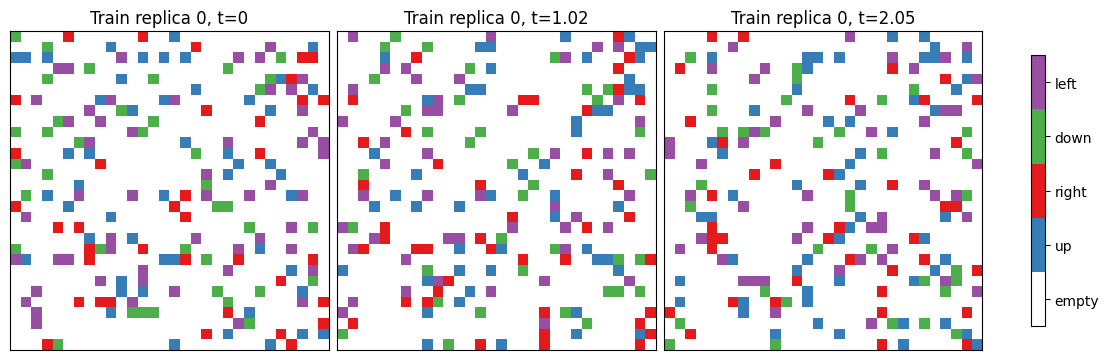

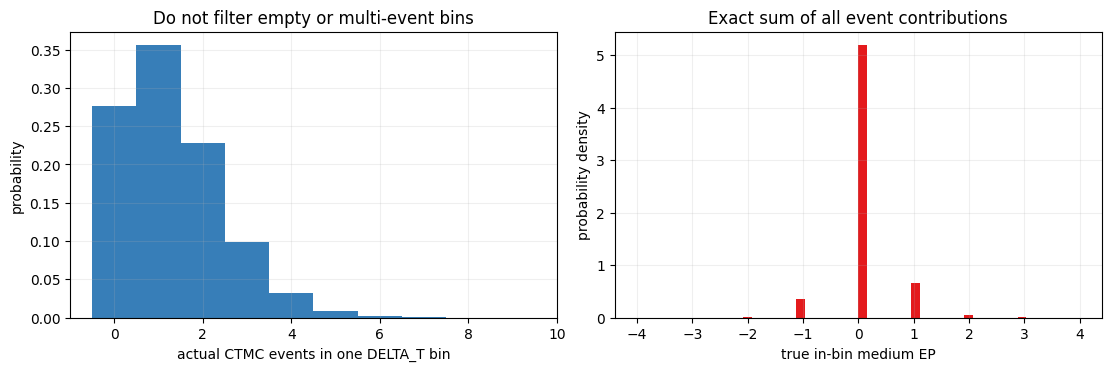

{
  "train": {
    "true_ep_rate_first_half_mean_sem": [
      29.913902282714844,
      0.2632358878620835
    ],
    "true_ep_rate_second_half_mean_sem": [
      30.117034912109375,
      0.2570088742210837
    ]
  },
  "validation": {
    "true_ep_rate_first_half_mean_sem": [
      30.338287353515625,
      0.5280942859385274
    ],
    "true_ep_rate_second_half_mean_sem": [
      30.170440673828125,
      0.5268241237009073
    ]
  },
  "test": {
    "true_ep_rate_first_half_mean_sem": [
      24.71923828125,
      2.5694278481666313
    ],
    "true_ep_rate_second_half_mean_sem": [
      32.5927734375,
      2.3159068675227203
    ]
  }
}


In [ ]:
direction_cmap = ListedColormap(["white", "#377eb8", "#e41a1c", "#4daf4a", "#984ea3"])
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5), constrained_layout=True)
for ax, frame in zip(axes, (0, N_FRAMES // 2, N_FRAMES - 1)):
    image = ax.imshow(
        results["train"].states[0, frame] + 1, cmap=direction_cmap,
        vmin=-0.5, vmax=4.5, interpolation="nearest",
    )
    ax.set_title(f"Train replica 0, t={results['train'].times[frame]:.3g}")
    ax.set_xticks([])
    ax.set_yticks([])
bar = fig.colorbar(image, ax=axes, ticks=range(5), shrink=0.85)
bar.ax.set_yticklabels(["empty", "up", "right", "down", "left"])
fig.savefig(RESULT_DIR / "fixed_time_direction_snapshots.png", dpi=150)
plt.show()

def mean_sem(values):
    values = np.asarray(values, dtype=np.float64)
    return float(values.mean()), float(values.std(ddof=1) / np.sqrt(len(values)))

train_event_count = results["train"].hop_counts + results["train"].rotation_counts
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
axes[0].hist(train_event_count.ravel(), bins=np.arange(train_event_count.max() + 2) - .5,
             density=True, color="#377eb8")
axes[0].set(xlabel="actual CTMC events in one DELTA_T bin", ylabel="probability",
            title="Do not filter empty or multi-event bins")
axes[1].hist(true_ep_by_split["train"].ravel(), bins=50, density=True, color="#e41a1c")
axes[1].set(xlabel="true in-bin medium EP", ylabel="probability density",
            title="Exact sum of all event contributions")
for ax in axes:
    ax.grid(alpha=.2)
fig.savefig(RESULT_DIR / "fixed_time_bin_diagnostics.png", dpi=150)
plt.show()

drift_diagnostics = {}
midpoint = N_INTERVALS // 2
for name, result in results.items():
    first_rate = result.medium_ep[:, :midpoint].sum(axis=1) / (midpoint * DELTA_T)
    second_rate = result.medium_ep[:, midpoint:].sum(axis=1) / ((N_INTERVALS - midpoint) * DELTA_T)
    drift_diagnostics[name] = {
        "true_ep_rate_first_half_mean_sem": mean_sem(first_rate),
        "true_ep_rate_second_half_mean_sem": mean_sem(second_rate),
    }
print(json.dumps(drift_diagnostics, indent=2))


## 4. Unsupervised training on sampled endpoint pairs

A batch selects a replica and a physical-time bin uniformly.  It uses only
the endpoint observations `X(t_j), X(t_j + DELTA_T)`; `true_ep` never
enters the loss.  This retains fixed-time no-event pairs and bins with
hidden multiple-event paths.  The model returns spatial means, which are
multiplied by lattice area to form extensive score increments.


In [ ]:
torch.manual_seed(TRAIN_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(TRAIN_SEED)
pair_rng = torch.Generator(device="cpu").manual_seed(TRAIN_SEED + 1)
model = MultiScaleShellForceCNEEP2D(opt).to(DEVICE)
# Begin at a precisely zero extensive-score baseline.
for branch in model.branches:
    torch.nn.init.zeros_(branch.force_head[-1].weight)
    if branch.force_head[-1].bias is not None:
        torch.nn.init.zeros_(branch.force_head[-1].bias)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

def pair_batch(video, replica_index, interval_index):
    packed = torch.stack(
        (video[replica_index, interval_index], video[replica_index, interval_index + 1]), dim=1
    ).to(DEVICE)
    directions = torch.arange(4, device=DEVICE, dtype=packed.dtype).view(1, 1, 4, 1, 1)
    return (packed.unsqueeze(2) == directions).to(torch.float32)

def random_pairs(video, batch_size):
    replica = torch.randint(video.shape[0], (batch_size,), generator=pair_rng)
    interval = torch.randint(N_INTERVALS, (batch_size,), generator=pair_rng)
    return pair_batch(video, replica, interval)

def ordered_pairs(video, batch_size):
    for start in range(0, video.shape[0] * N_INTERVALS, batch_size):
        index = torch.arange(start, min(start + batch_size, video.shape[0] * N_INTERVALS))
        yield index // N_INTERVALS, index % N_INTERVALS

def alpha_neep_terms(score):
    if ALPHA == 0:
        return -score + torch.expm1(-score)
    if not -1 < ALPHA < 0:
        raise ValueError("Choose ALPHA=0 or -1 < ALPHA < 0.")
    return -torch.expm1(ALPHA * score) / ALPHA + torch.expm1(-(1 + ALPHA) * score) / (1 + ALPHA)

def branch_scores(batch):
    return model(batch) * AREA  # spatial mean -> extensive score increment

@torch.no_grad()
def evaluate_objective(video):
    model.eval()
    total, count = 0.0, 0
    for replica, interval in ordered_pairs(video, EVAL_BATCH_SIZE):
        score = branch_scores(pair_batch(video, replica, interval)).sum(dim=1)
        total += alpha_neep_terms(score).double().sum().item()
        count += len(score)
    return total / count

with torch.no_grad():
    check = pair_batch(train_video, torch.tensor([0, 1]), torch.tensor([0, 0]))
    expected = encode_observations(results["train"].states[[0, 1], :2]).to(DEVICE)
    torch.testing.assert_close(check, expected, rtol=0, atol=0)
    branch = branch_scores(check)
    assert torch.count_nonzero(branch).item() == 0
    raw_maps = model(check, return_maps=True)
    assert branch.shape == (2, MODEL_MAX_DISTANCE + 1)
    torch.testing.assert_close(branch, raw_maps.sum(dim=(-2, -1)), atol=2e-5, rtol=2e-5)
    torch.testing.assert_close(branch_scores(check.flip(1)), -branch, atol=2e-5, rtol=2e-5)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")
print("Fixed-time pair boundaries, map normalization, and reversal checks passed.")


Parameters: 447,512
Fixed-time pair boundaries, map normalization, and reversal checks passed.


In [ ]:
history = {"iteration": [0], "train": [0.0], "validation": [0.0]}
best_val, best_iteration = 0.0, 0
checkpoint_path = RESULT_DIR / "best_model.pt"

def save_checkpoint(iteration, validation_loss):
    torch.save(
        {
            "state_dict": model.state_dict(),
            "model_options": vars(opt),
            "iteration": iteration,
            "validation_loss": validation_loss,
            "physics": asdict(config),
            "sampling_mode": "fixed_time_ctmc",
            "delta_t": DELTA_T,
            "n_intervals": N_INTERVALS,
            "burn_time": BURN_TIME,
            "simulation_backend": SIMULATION_BACKEND,
            "simulator_sha256": SIMULATOR_HASH,
            "cache_ids": dict(cache_ids),
            "train_seed": TRAIN_SEED,
            "alpha": ALPHA,
            "score_convention": "spatial_mean_times_area",
            "initialization": "zero final force heads; random hidden features",
        },
        checkpoint_path,
    )

save_checkpoint(0, best_val)
recent_losses = []
progress = trange(1, N_ITER + 1, desc="fixed-time alpha-NEEP", disable=SMOKE)
for iteration in progress:
    model.train()
    optimizer.zero_grad(set_to_none=True)
    score = branch_scores(random_pairs(train_video, BATCH_SIZE)).sum(dim=1)
    loss = alpha_neep_terms(score).mean()
    if not torch.isfinite(loss):
        raise FloatingPointError("Nonfinite alpha-NEEP loss; lower the learning rate.")
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP_NORM, error_if_nonfinite=True)
    optimizer.step()
    recent_losses.append(float(loss.detach()))
    if iteration % RECORD_EVERY == 0 or iteration == N_ITER:
        validation_loss = evaluate_objective(val_video)
        if not math.isfinite(validation_loss):
            raise FloatingPointError("Nonfinite validation loss.")
        history["iteration"].append(iteration)
        history["train"].append(float(np.mean(recent_losses)))
        history["validation"].append(validation_loss)
        recent_losses.clear()
        if validation_loss < best_val:
            best_val, best_iteration = validation_loss, iteration
            save_checkpoint(iteration, validation_loss)
        progress.set_postfix(validation=f"{validation_loss:.4g}", best=best_iteration)

checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
model.load_state_dict(checkpoint["state_dict"])
model.eval()
print(f"Best iteration={best_iteration}, validation objective={best_val:.6g}, zero-score baseline=0")
if best_val >= -1e-6:
    warnings.warn("Validation did not improve over zero; treat held-out plots as unresolved-learning diagnostics.")


fixed-time alpha-NEEP:   0%|          | 0/4000 [00:00<?, ?it/s]

Best iteration=4000, validation objective=-0.0227684, zero-score baseline=0


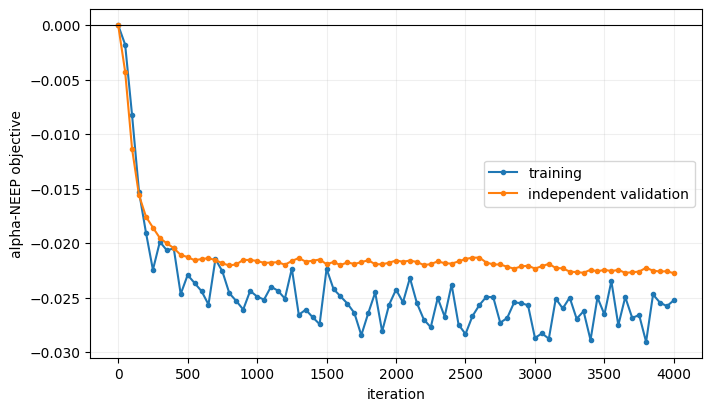

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
ax.plot(history["iteration"], history["train"], ".-", label="training")
ax.plot(history["iteration"], history["validation"], ".-", label="independent validation")
ax.axhline(0, color="k", lw=.8)
ax.set(xlabel="iteration", ylabel="alpha-NEEP objective")
ax.legend()
ax.grid(alpha=.2)
fig.savefig(RESULT_DIR / "training_objective.png", dpi=150)
plt.show()

## 5. Held-out fixed-time score versus true in-bin medium EP

Each held-out `true_ep` value is the exact sum of all actual event
contributions in its physical-time bin.  The learned score sees only the
sampled endpoints, so equality per bin is not expected after coarse
graining.  Both quantities are converted to rates by dividing their
trajectory sums by the common physical duration
`N_INTERVALS * DELTA_T`.


{
  "exact_true_ep_rate_mean_sem": [
    28.656005859375,
    1.102440909923611
  ],
  "learned_sampled_endpoint_score_rate_mean_sem": [
    11.976712584495544,
    0.8341467366182551
  ],
  "exact_true_ep_per_interval_mean_sem": [
    0.05731201171875,
    0.002204881819847222
  ],
  "learned_score_per_interval_mean_sem": [
    0.023953426687512547,
    0.0016682936206936204
  ],
  "pooled_exact_true_ep_rate": 28.656005859375,
  "pooled_learned_score_rate": 11.976713180541992,
  "rate_difference_mean_sem": [
    -16.679293274879456,
    1.0660617695798562
  ]
}
Held-out alpha-NEEP objective=-0.0207853; zero-score baseline=0.


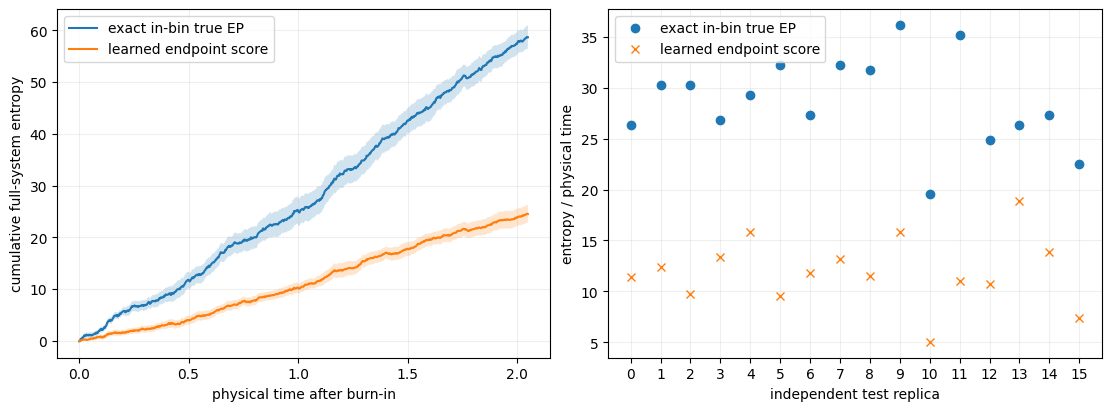

In [ ]:
@torch.no_grad()
def predict_ensemble(video):
    model.eval()
    total_pairs = video.shape[0] * N_INTERVALS
    branch_output = np.empty((total_pairs, MODEL_MAX_DISTANCE + 1), dtype=np.float32)
    local_output = np.empty((total_pairs, config.lattice_size, config.lattice_size), dtype=np.float32)
    offset = 0
    for replica, interval in ordered_pairs(video, EVAL_BATCH_SIZE):
        raw = model(pair_batch(video, replica, interval), return_maps=True)
        if not torch.isfinite(raw).all():
            raise FloatingPointError("Nonfinite held-out prediction.")
        branches = raw.sum(dim=(-2, -1))
        local = raw.sum(dim=1)
        torch.testing.assert_close(local.sum(dim=(-2, -1)), branches.sum(dim=1), atol=2e-5, rtol=2e-5)
        end = offset + len(branches)
        branch_output[offset:end] = branches.cpu().numpy()
        local_output[offset:end] = local.cpu().numpy()
        offset = end
    assert offset == total_pairs
    return (
        branch_output.reshape(video.shape[0], N_INTERVALS, MODEL_MAX_DISTANCE + 1),
        local_output.reshape(video.shape[0], N_INTERVALS, config.lattice_size, config.lattice_size),
    )

pred_branches, pred_local = predict_ensemble(test_video)
pred_total = pred_branches.sum(axis=-1)
reference = results["test"]
true_ep = reference.medium_ep  # exact all-event medium-EP sum within each DELTA_T interval
true_local = reference.medium_ep_maps
np.testing.assert_allclose(true_local.sum(axis=(-2, -1)), true_ep, atol=1e-9)
np.testing.assert_allclose(pred_local.sum(axis=(-2, -1)), pred_total, rtol=2e-5, atol=2e-5)

observation_duration = N_INTERVALS * DELTA_T
true_replica_rates = true_ep.sum(axis=1) / observation_duration
pred_replica_rates = pred_total.sum(axis=1) / observation_duration
rate_summary = {
    "exact_true_ep_rate_mean_sem": mean_sem(true_replica_rates),
    "learned_sampled_endpoint_score_rate_mean_sem": mean_sem(pred_replica_rates),
    "exact_true_ep_per_interval_mean_sem": mean_sem(true_ep.mean(axis=1)),
    "learned_score_per_interval_mean_sem": mean_sem(pred_total.mean(axis=1)),
    "pooled_exact_true_ep_rate": float(true_ep.sum() / (TEST_M * observation_duration)),
    "pooled_learned_score_rate": float(pred_total.sum() / (TEST_M * observation_duration)),
    "rate_difference_mean_sem": mean_sem(pred_replica_rates - true_replica_rates),
}
test_objective = evaluate_objective(test_video)
print(json.dumps(rate_summary, indent=2))
print(f"Held-out alpha-NEEP objective={test_objective:.6g}; zero-score baseline=0.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
interval_times = reference.times[1:]
for values, label in ((true_ep.cumsum(axis=1), "exact in-bin true EP"),
                      (pred_total.cumsum(axis=1), "learned endpoint score")):
    average = values.mean(axis=0)
    error = values.std(axis=0, ddof=1) / np.sqrt(TEST_M)
    axes[0].plot(interval_times, average, label=label)
    axes[0].fill_between(interval_times, average - error, average + error, alpha=.2)
axes[0].set(xlabel="physical time after burn-in", ylabel="cumulative full-system entropy")
axes[0].legend()
axes[0].grid(alpha=.2)
replicas = np.arange(TEST_M)
axes[1].plot(replicas, true_replica_rates, "o", label="exact in-bin true EP")
axes[1].plot(replicas, pred_replica_rates, "x", label="learned endpoint score")
axes[1].set(xlabel="independent test replica", ylabel="entropy / physical time")
axes[1].set_xticks(replicas)
axes[1].legend()
axes[1].grid(alpha=.2)
fig.savefig(RESULT_DIR / "held_out_fixed_time_entropy_rates.png", dpi=150)
plt.show()


## 6. Signed shell spectrum and local maps

The simulator's exact algebraic decomposition has a zero reserved local
slot, a forward/backward baseline in shell 1, and forward-sensing terms at
their physical distances.  It is a diagnostic decomposition, not a
shell-wise training target.  Exact local maps split a hop contribution
between source and target; learned maps use convolution centers.


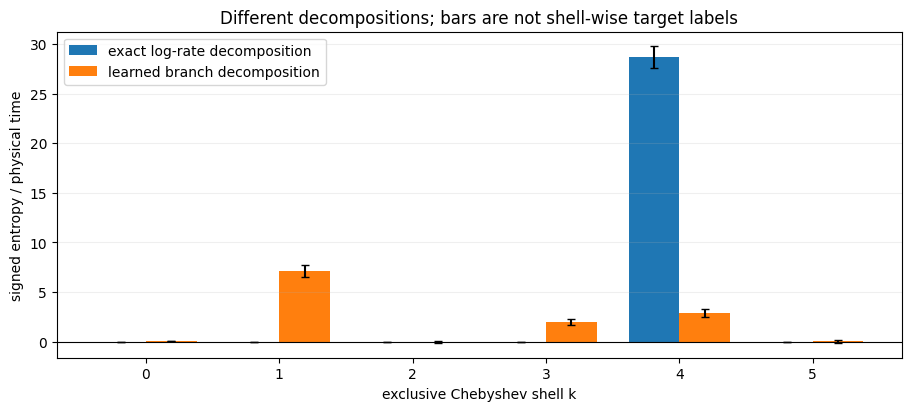

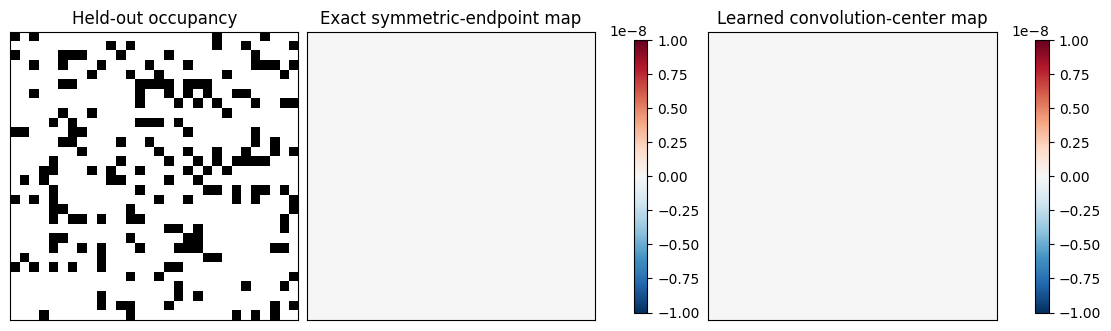

In [ ]:
distances = np.arange(MODEL_MAX_DISTANCE + 1)
learned_replica_shell_rates = pred_branches.sum(axis=1) / observation_duration
exact_replica_shell_rates = np.zeros_like(learned_replica_shell_rates, dtype=np.float64)
exact_width = reference.shell_ep.shape[-1]
exact_replica_shell_rates[:, :exact_width] = reference.shell_ep.sum(axis=1) / observation_duration
learned_shell_mean = learned_replica_shell_rates.mean(axis=0)
learned_shell_sem = learned_replica_shell_rates.std(axis=0, ddof=1) / np.sqrt(TEST_M)
exact_shell_mean = exact_replica_shell_rates.mean(axis=0)
exact_shell_sem = exact_replica_shell_rates.std(axis=0, ddof=1) / np.sqrt(TEST_M)
np.testing.assert_allclose(exact_shell_mean.sum(), true_replica_rates.mean(), atol=1e-9)
np.testing.assert_allclose(learned_shell_mean.sum(), pred_replica_rates.mean(), rtol=2e-5, atol=2e-5)

fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
ax.bar(distances - .19, exact_shell_mean, width=.38, yerr=exact_shell_sem,
       capsize=3, label="exact log-rate decomposition")
ax.bar(distances + .19, learned_shell_mean, width=.38, yerr=learned_shell_sem,
       capsize=3, label="learned branch decomposition")
ax.axhline(0, color="k", lw=.8)
ax.set(xlabel="exclusive Chebyshev shell k", ylabel="signed entropy / physical time",
       title="Different decompositions; bars are not shell-wise target labels")
ax.set_xticks(distances)
ax.legend()
ax.grid(axis="y", alpha=.2)
fig.savefig(RESULT_DIR / "chebyshev_shell_spectrum.png", dpi=150)
plt.show()

replica_index = 0
interval_index = N_INTERVALS // 2
local_reference = true_local[replica_index, interval_index]
local_prediction = pred_local[replica_index, interval_index]
limit = max(float(np.abs(local_reference).max()), float(np.abs(local_prediction).max()), 1e-8)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5), constrained_layout=True)
axes[0].imshow(reference.states[replica_index, interval_index] >= 0, cmap="Greys", vmin=0, vmax=1)
axes[0].set_title("Held-out occupancy")
for ax, field, label in zip(
    axes[1:], (local_reference, local_prediction),
    ("Exact symmetric-endpoint map", "Learned convolution-center map"),
):
    im = ax.imshow(field, cmap="RdBu_r", vmin=-limit, vmax=limit)
    ax.set_title(label)
    fig.colorbar(im, ax=ax, shrink=.8)
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
fig.savefig(RESULT_DIR / "local_entropy_maps.png", dpi=150)
plt.show()


## 7. Save reproducible diagnostics

The outputs preserve the observation grid, event counts, exact true EP,
exact local/shell decompositions, sampled endpoint scores, source hashes,
and cache identities.  Re-run with a different `DELTA_T` to study temporal
coarse graining; the cache key changes automatically.


In [ ]:
summary = {
    "physics": asdict(config),
    "simulation": {
        "algorithm": "exact Gillespie direct method",
        "sampling_mode": "fixed_time_ctmc",
        "delta_t": DELTA_T,
        "n_frames": N_FRAMES,
        "n_intervals": N_INTERVALS,
        "burn_time": BURN_TIME,
        "observation_duration": observation_duration,
        "workers": WORKERS,
        "simulation_backend_request": SIMULATION_BACKEND_REQUEST,
        "simulation_backend": SIMULATION_BACKEND,
        "cuda_batch_size": CUDA_BATCH_SIZE,
        "split_seeds": SPLIT_SEEDS,
        "replicas": {"train": TRAIN_M, "validation": VAL_M, "test": TEST_M},
        "true_ep_definition": (
            "medium_ep[m,j] is the sum of log forward/reverse-rate ratios "
            "for every actual CTMC event in (t_j, t_{j+1}]; burn-in events excluded"
        ),
    },
    "training": {
        "model": "MultiScaleShellForceCNEEP2D",
        "options": vars(opt),
        "iterations": N_ITER,
        "batch_size": BATCH_SIZE,
        "seed": TRAIN_SEED,
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "alpha": ALPHA,
        "best_iteration": best_iteration,
        "best_validation_objective": best_val,
        "test_objective": test_objective,
        "score_convention": "branch spatial means times lattice area",
        "true_ep_used_as_supervised_target": False,
    },
    "cache_ids": cache_ids,
    "simulator_sha256": SIMULATOR_HASH,
    "cuda_source_sha256": CUDA_SOURCE_HASH,
    "model_sha256": hashlib.sha256((ROOT / "models" / "NEEP_ShellForce_2D.py").read_bytes()).hexdigest(),
    "sanity_source_sha256": SANITY_SOURCE_HASH,
    "sampling_diagnostics": sampling_diagnostics,
    "drift_diagnostics": drift_diagnostics,
    "rates": rate_summary,
    "learned_shell_rate_mean": learned_shell_mean.tolist(),
    "learned_shell_rate_sem": learned_shell_sem.tolist(),
    "exact_shell_rate_mean": exact_shell_mean.tolist(),
    "exact_shell_rate_sem": exact_shell_sem.tolist(),
    "smoke": SMOKE,
    "interpretation": (
        "Fixed-time endpoint irreversibility is evaluated against exact in-bin microscopic "
        "medium path entropy; temporal coarse graining and stationary endpoint terms remain."
    ),
}
(RESULT_DIR / "summary.json").write_text(json.dumps(summary, indent=2, allow_nan=False), encoding="utf-8")
np.savez_compressed(
    RESULT_DIR / "held_out_diagnostics.npz",
    times=reference.times,
    states=reference.states,
    hop_counts=reference.hop_counts,
    rotation_counts=reference.rotation_counts,
    true_ep=true_ep,
    true_ep_maps=true_local,
    true_shell_ep=reference.shell_ep,
    learned_total_increment=pred_total,
    learned_local_increment=pred_local,
    learned_shell_increment=pred_branches,
    true_replica_rates=true_replica_rates,
    learned_replica_rates=pred_replica_rates,
    history_iteration=np.asarray(history["iteration"]),
    history_train=np.asarray(history["train"]),
    history_validation=np.asarray(history["validation"]),
)
plt.close("all")
print("Saved checkpoint and diagnostics:", RESULT_DIR)
print("Smoke complete." if SMOKE else "Training run complete; inspect held-out and relaxation diagnostics.")


Saved checkpoint and diagnostics: /home/user1/projects/CNEEP_v2/results/Corr_labpm_ctmc/20261001T050655_690259Z
Training run complete; inspect held-out and relaxation diagnostics.
